<a href="https://colab.research.google.com/github/eduardoj14/Classificador-de-RG/blob/main/Projeto_rgs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importando as bibliotecas

from pathlib import Path
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [ ]:
#localizando as imagens e montando o dataframe

BASE_DIR = Path("/content/arquivos_rg")
CLASSES = ["rg_antigo", "rg_novo", "invalidos"]
EXTENSOES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

dados = []

for classe in CLASSES:
    pasta = BASE_DIR / classe

    if not pasta.exists():
        print(f"ATENÇÃO: pasta não encontrada: {pasta}")
        continue

    for arquivo in pasta.rglob("*"):
        if arquivo.is_file() and arquivo.suffix.lower() in EXTENSOES:
            dados.append({
                "arquivo": str(arquivo),
                "classe": classe
            })

df = pd.DataFrame(dados)

if df.empty:
    print("\nNenhuma imagem foi encontrada.")
    print("Confira se BASE_DIR e os nomes das pastas estão corretos.")
else:
    print("Total de imagens encontradas:", len(df))
    display(df.head())
    print("\nQuantidade por classe:")
    display(df["classe"].value_counts().rename_axis("classe").reset_index(name="quantidade"))

Total de imagens encontradas: 300


,arquivo,classe
0,/content/arquivos_rg/rg_antigo/00022258_in.jpg,rg_antigo
1,/content/arquivos_rg/rg_antigo/00022284_in.jpg,rg_antigo
2,/content/arquivos_rg/rg_antigo/00022282_in.jpg,rg_antigo
3,/content/arquivos_rg/rg_antigo/00022209_in.jpg,rg_antigo
4,/content/arquivos_rg/rg_antigo/00022193_in.jpg,rg_antigo



Quantidade por classe:


,classe,quantidade
0,rg_antigo,100
1,rg_novo,100
2,invalidos,100


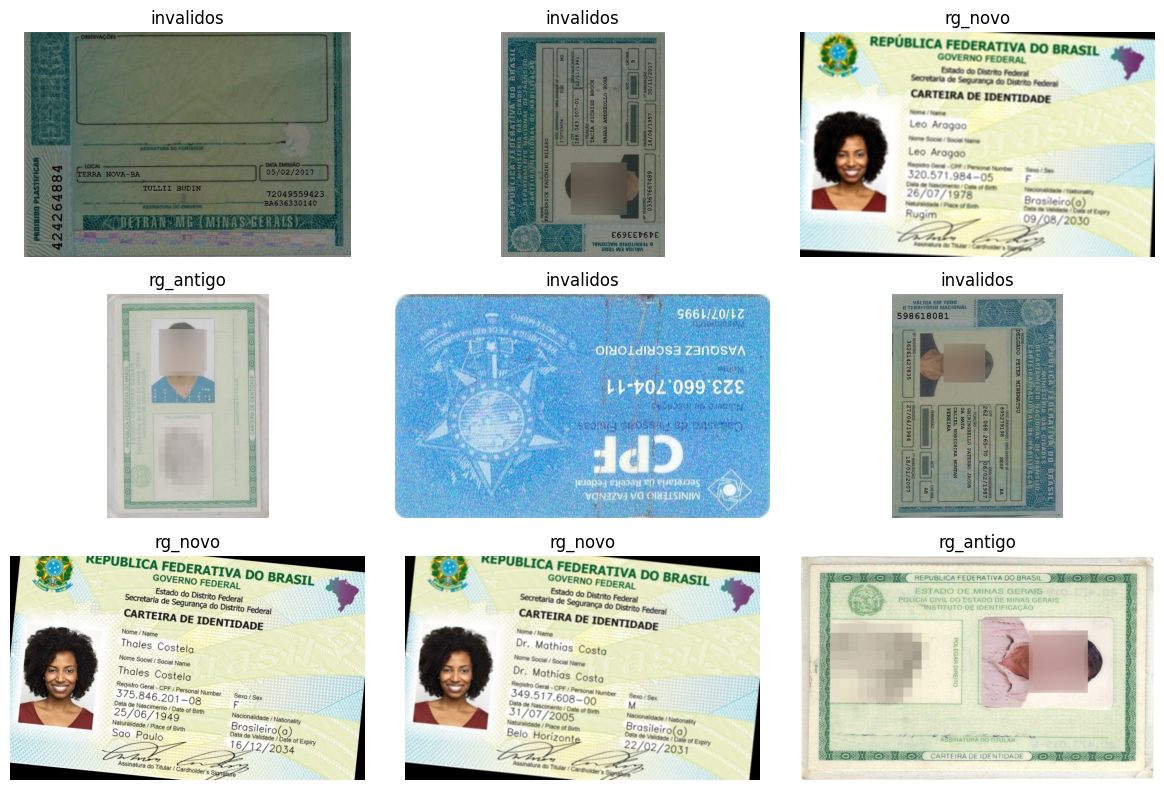

In [ ]:
#conferindo as imagens

if not df.empty:
    amostra = df.sample(n=min(9, len(df)), random_state=42)

    plt.figure(figsize=(12, 8))
    for i, (_, linha) in enumerate(amostra.iterrows(), start=1):
        imagem = cv2.imread(linha["arquivo"])
        if imagem is None:
            continue

        imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)
        plt.subplot(3, 3, i)
        plt.imshow(imagem)
        plt.title(linha["classe"])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
#preparando as imagens para o treinamento

TAMANHO = (64, 64)
LIMITE_POR_CLASSE = 100

if df.empty:
    raise ValueError("O DataFrame está vazio. Corrija o caminho das imagens antes de continuar.")

df_modelo = (
    df.groupby("classe", group_keys=False)
      .apply(lambda grupo: grupo.sample(
          n=min(len(grupo), LIMITE_POR_CLASSE),
          random_state=42
      ), include_groups=False)
      .reset_index(drop=True)
)

# Recria a coluna classe caso a versão do Pandas não a mantenha no groupby/apply
if "classe" not in df_modelo.columns:
    df_modelo = df.loc[df.index.intersection(df_modelo.index)].copy()

imagens_processadas = []
rotulos = []
caminhos_validos = []
erros = 0

for _, linha in df.iterrows():
    # Limita a quantidade por classe de forma reproduzível
    pass

for classe in CLASSES:
    grupo = df[df["classe"] == classe].sample(
        n=min(len(df[df["classe"] == classe]), LIMITE_POR_CLASSE),
        random_state=42
    )

    if len(grupo) < LIMITE_POR_CLASSE:
        print(f"ATENÇÃO: {classe} tem {len(grupo)} imagem(ns), não 100.")

    for _, linha in grupo.iterrows():
        imagem = cv2.imread(linha["arquivo"])

        if imagem is None:
            erros += 1
            continue

        imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2GRAY)
        imagem = cv2.resize(imagem, TAMANHO)
        imagem = imagem.astype("float32") / 255.0

        imagens_processadas.append(imagem.flatten())
        rotulos.append(classe)
        caminhos_validos.append(linha["arquivo"])

X = np.array(imagens_processadas)
y = np.array(rotulos)

df_final = pd.DataFrame({
    "arquivo": caminhos_validos,
    "classe": y
})

print("Imagens carregadas:", len(y))
print("Imagens que não puderam ser abertas:", erros)
print("\nQuantidade efetivamente usada por classe:")
display(df_final["classe"].value_counts().rename_axis("classe").reset_index(name="quantidade"))

if len(set(y)) < 3:
    raise ValueError("É necessário ter imagens válidas nas três classes para continuar.")

print("Formato de X (imagens x características):", X.shape)
print("Formato de y (rótulos):", y.shape)

Imagens carregadas: 300
Imagens que não puderam ser abertas: 0

Quantidade efetivamente usada por classe:


,classe,quantidade
0,rg_antigo,100
1,rg_novo,100
2,invalidos,100


Formato de X (imagens x características): (300, 4096)
Formato de y (rótulos): (300,)


In [ ]:
#separando treino e teste

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Imagens para treino:", len(y_treino))
print("Imagens para teste:", len(y_teste))
print("\nClasses no conjunto de teste:")
display(pd.Series(y_teste).value_counts().rename_axis("classe").reset_index(name="quantidade"))

Imagens para treino: 240
Imagens para teste: 60

Classes no conjunto de teste:


,classe,quantidade
0,invalidos,20
1,rg_novo,20
2,rg_antigo,20


In [ ]:
#criando os três modelos

modelos = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced", random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

print("Modelos preparados:", ", ".join(modelos.keys()))

Modelos preparados: SVM, Random Forest, KNN


In [30]:
#Treinando e avaliando os modelos
resultados = []
previsoes = {}

for nome, modelo in modelos.items():
    print(f"Treinando: {nome}")
    modelo.fit(X_treino, y_treino)

    y_previsto = modelo.predict(X_teste)
    previsoes[nome] = y_previsto

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, y_previsto),
        "Precisão macro": precision_score(y_teste, y_previsto, average="macro", zero_division=0),
        "Recall macro": recall_score(y_teste, y_previsto, average="macro", zero_division=0),
        "F1-score macro": f1_score(y_teste, y_previsto, average="macro", zero_division=0)
    })

comparacao = pd.DataFrame(resultados).sort_values(
    by="F1-score macro",
    ascending=False
).reset_index(drop=True)

display(comparacao.round(3))

Treinando: SVM
Treinando: Random Forest
Treinando: KNN


,Modelo,Acurácia,Precisão macro,Recall macro,F1-score macro
0,SVM,0.950,0.957,0.950,0.950
1,Random Forest,0.933,0.936,0.933,0.933
2,KNN,0.833,0.850,0.833,0.829


In [31]:
#Relatório por classe
for nome, y_previsto in previsoes.items():
    print("=" * 60)
    print("MODELO:", nome)
    print(classification_report(
        y_teste,
        y_previsto,
        labels=CLASSES,
        target_names=CLASSES,
        zero_division=0,
        digits=3
    ))

MODELO: SVM
              precision    recall  f1-score   support

   rg_antigo      1.000     0.850     0.919        20
     rg_novo      1.000     1.000     1.000        20
   invalidos      0.870     1.000     0.930        20

    accuracy                          0.950        60
   macro avg      0.957     0.950     0.950        60
weighted avg      0.957     0.950     0.950        60

MODELO: Random Forest
              precision    recall  f1-score   support

   rg_antigo      0.944     0.850     0.895        20
     rg_novo      1.000     1.000     1.000        20
   invalidos      0.864     0.950     0.905        20

    accuracy                          0.933        60
   macro avg      0.936     0.933     0.933        60
weighted avg      0.936     0.933     0.933        60

MODELO: KNN
              precision    recall  f1-score   support

   rg_antigo      0.692     0.900     0.783        20
     rg_novo      1.000     1.000     1.000        20
   invalidos      0.857     0